In [ ]:
# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
# 2. Load dataset
dataset = pd.read_csv("synthetic_mobile_money_transaction_dataset_cleaned.csv")

print("Dataset Shape:", dataset.shape)
print(dataset.head())
dataset.info()

Dataset Shape: (1649311, 12)
   step transactionType    amount         initiator  oldBalInitiator  \
0     0        TRANSFER  19824.96  4537027967639631        187712.18   
1     0         PAYMENT    598.97  4296267625767470             8.92   
2     0         PAYMENT    545.85  4178224023847746            93.60   
3     0        TRANSFER  19847.01  4178224023847746          -452.25   
4     0         PAYMENT    546.89  4779013371563747        159148.76   

   newBalInitiator         recipient  oldBalRecipient  newBalRecipient  \
0        167887.22  4875702729424478             8.31         19833.27   
1             8.92        25-0000401             0.00             0.00   
2          -452.25        13-0001587             0.00           545.85   
3        -20299.26  4096920916696293          4011.72         23858.74   
4        158601.88        75-0003564             0.00           546.89   

   isFraud  initiator_balance_change  recipient_balance_change  
0      1.0                  

In [ ]:
# 3. Check missing values and duplicates
print(dataset.isnull().sum())
print("Duplicate Rows:", dataset.duplicated().sum())

dataset = dataset.dropna(subset=["isFraud"]).drop_duplicates().copy()
dataset["isFraud"] = dataset["isFraud"].astype(int)

step                        0
transactionType             0
amount                      0
initiator                   0
oldBalInitiator             0
newBalInitiator             0
recipient                   0
oldBalRecipient             0
newBalRecipient             0
isFraud                     0
initiator_balance_change    0
recipient_balance_change    0
dtype: int64
Duplicate Rows: 0


isFraud
0    1478348
1     170963
Name: count, dtype: int64
isFraud
0    89.63
1    10.37
Name: proportion, dtype: float64
isFraud               0       1
transactionType                
DEBIT              4909       0
DEPOSIT          362158       0
PAYMENT          643781       0
TRANSFER         381826  170963
WITHDRAWAL        85674       0


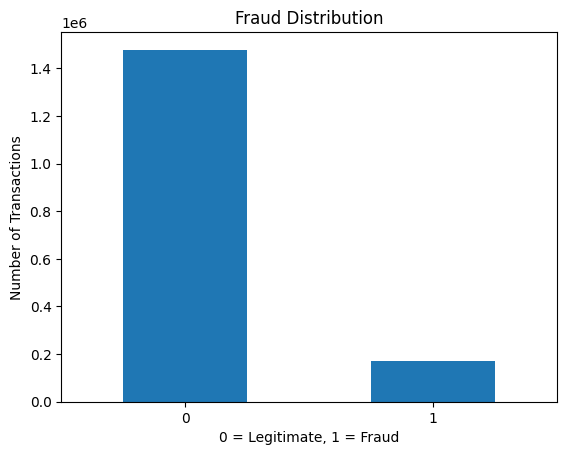

In [ ]:
# 4. Explore fraud distribution
print(dataset["isFraud"].value_counts())
print((dataset["isFraud"].value_counts(normalize=True) * 100).round(2))

print(pd.crosstab(dataset["transactionType"], dataset["isFraud"]))

dataset["isFraud"].value_counts().sort_index().plot(kind="bar", rot=0)
plt.title("Fraud Distribution")
plt.xlabel("0 = Legitimate, 1 = Fraud")
plt.ylabel("Number of Transactions")
plt.show()

In [ ]:
# 5. Select features and target
features = [
    "step", "amount", "oldBalInitiator",
    "newBalInitiator", "oldBalRecipient", "newBalRecipient"
]

X = dataset[features]
y = dataset["isFraud"]

In [ ]:
# 6. Chronological train-test split
steps = sorted(dataset["step"].unique())
test_start = steps[int(len(steps) * 0.80)]

train = dataset["step"] < test_start
test = dataset["step"] >= test_start

train_sample = dataset.loc[train].sample(
    n=min(100000, int(train.sum())),
    random_state=42
)

X_train = train_sample[features]
y_train = train_sample["isFraud"]
X_test = X.loc[test]
y_test = y.loc[test]

print("Training Rows:", len(X_train))
print("Testing Rows:", len(X_test))

Training Rows: 100000
Testing Rows: 311676


In [ ]:
# 7. Logistic Regression
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

classifier = LogisticRegression(
    class_weight="balanced", max_iter=300, random_state=42
)
classifier.fit(X_train_scaled, y_train)
y_pred = classifier.predict(X_test_scaled)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))

Confusion Matrix:
 [[138337 139130]
 [  1597  32612]]
Accuracy: 0.5484830400800832
Precision: 0.18988948539087702
Recall: 0.9533163787307434
F1-Score: 0.3166966899893664


In [ ]:
# 8. Decision Tree
classifier = DecisionTreeClassifier(
    max_depth=12, min_samples_leaf=100,
    class_weight="balanced", random_state=42
)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))

Confusion Matrix:
 [[190450  87017]
 [   110  34099]]
Accuracy: 0.7204564996984048
Precision: 0.28154001122890454
Recall: 0.9967844719225935
F1-Score: 0.43906647352325767


In [ ]:
# 9. Naive Bayes
classifier = GaussianNB()
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))

Confusion Matrix:
 [[125840 151627]
 [  2753  31456]]
Accuracy: 0.5046779347784237
Precision: 0.17181278436556097
Recall: 0.9195241018445438
F1-Score: 0.2895274561419656


In [ ]:
# 10. K-Nearest Neighbors
knn_sample = train_sample.sample(
    n=min(20000, len(train_sample)), random_state=42
)

sc = StandardScaler()
X_knn_train = sc.fit_transform(knn_sample[features])
X_knn_test = sc.transform(X_test)

classifier = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
classifier.fit(X_knn_train, knn_sample["isFraud"])
y_pred = classifier.predict(X_knn_test)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))

Confusion Matrix:
 [[257920  19547]
 [ 28833   5376]]
Accuracy: 0.8447747019340597
Precision: 0.21570436945793042
Recall: 0.15715162676488642
F1-Score: 0.181830480957857


In [ ]:
# 11. Linear SVM
sc = StandardScaler()
X_svm_train = sc.fit_transform(X_train)
X_svm_test = sc.transform(X_test)

classifier = LinearSVC(
    class_weight="balanced", max_iter=3000, random_state=42
)
classifier.fit(X_svm_train, y_train)
y_pred = classifier.predict(X_svm_test)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))

Confusion Matrix:
 [[ 93988 183479]
 [  1201  33008]]
Accuracy: 0.4074615947329919
Precision: 0.15247104906992107
Recall: 0.9648922798094068
F1-Score: 0.2633308868111178


In [ ]:
# 12. Random Forest
classifier = RandomForestClassifier(
    n_estimators=100, max_depth=16, min_samples_leaf=50,
    class_weight="balanced_subsample", n_jobs=-1, random_state=42
)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))

Confusion Matrix:
 [[192523  84944]
 [    91  34118]]
Accuracy: 0.7271685981596273
Precision: 0.28655658396465705
Recall: 0.9973398813177818
F1-Score: 0.4451983741216538


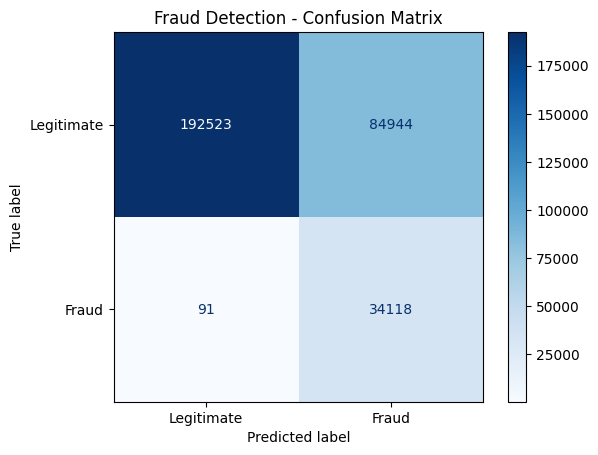

In [ ]:
# 13. Plot the final confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues"
)
plt.title("Fraud Detection - Confusion Matrix")
plt.show()
